# Relação das notas, escola, desejo de faculdade e sexo

# Desejo de ensino superior, região e sexo: relação com as notas

## Objetivo

Esta seção investiga como três características dos alunos (**desejo de cursar o ensino superior**, **região** e **sexo**) se relacionam com as notas do 1º período, do 2º período e com a nota final, nas disciplinas de Português e Matemática. Como as escolas **GP** e **MS** diferem em perfil e em desempenho, a análise foi feita **separadamente dentro de cada escola**, para verificar se as diferenças observadas se mantêm ou se eram apenas um reflexo da escola. Os alunos com nota zero foram mantidos.

## 1. Como as variáveis se relacionam entre si

O mapa de associações (V de Cramér) mostra que a **escola é a variável mais ligada às demais**: a maior associação do conjunto é entre escola e região (V = 0,35), seguida de escola e motivo da escolha da escola (0,28) e escola e profissão da mãe (0,24). Em Português, a MS tem 53% de alunos rurais, contra 18% na GP. Por isso, comparar rurais e urbanos sem separar por escola misturaria o efeito da região com o da escola. Já o desejo de cursar o ensino superior tem relação apenas fraca com a escola (V = 0,14).

## 2. Desejo de cursar o ensino superior

Esta foi a diferença mais marcante. Alunos que **não** desejam cursar o ensino superior têm notas médias consideravelmente menores. A tabela mostra a diferença de média (quem deseja menos quem não deseja), em pontos, em notas de 0 a 20:

| Disciplina | Escola | 1º período | 2º período | Final | Alunos que não desejam |
|---|---|---|---|---|---|
| Português | GP | 3,0 | 3,3 | 3,8 | 32 |
| Português | MS | 2,6 | 2,4 | 2,5 | 37 |
| Matemática | GP | 3,3 | 3,6 | 4,6 | 17 |

Todas as diferenças são estatisticamente sustentadas (Mann-Whitney, p < 0,001). A diferença **se mantém dentro de cada escola**, o que sugere que ela não é apenas um efeito da escola. Em Matemática, a escola MS tem somente 3 alunos que não desejam cursar o ensino superior, o que impede qualquer comparação nela.

## 3. Região

A região tem relação **pequena e pouco consistente** com as notas. Diferença de média (urbano menos rural):

| Disciplina | Escola | 1º período | 2º período | Final |
|---|---|---|---|---|
| Português | GP | 0,4 | 0,7* | 0,5* |
| Português | MS | 0,3 | 0,2 | 0,5 |
| Matemática | GP | 0,3 | 0,9 | 0,9 |
| Matemática | MS | 1,6 | 1,9 | 2,1 |

(* diferença estatisticamente sustentada, p < 0,05)

Em todas as combinações, os alunos rurais têm notas iguais ou menores que os urbanos, mas as diferenças são pequenas e, na maioria dos casos, **não se distinguem do acaso**. Em Matemática na MS, a diferença é maior, mas se baseia em apenas 25 alunos rurais e 21 urbanos.

## 4. Sexo

A relação do sexo com as notas **depende da disciplina**. Diferença de média em Português (mulheres menos homens):

| Escola | 1º período | 2º período | Final |
|---|---|---|---|
| GP | 0,7* | 0,8* | 1,0* |
| MS | 0,8 | 0,6 | 1,1 |

Em Português, as mulheres têm notas maiores nas duas escolas e em todos os períodos. Em Matemática, o padrão se inverte na GP: os **homens** têm notas cerca de 0,8 a 1,1 ponto maiores que as mulheres (p < 0,05). Na MS, em Matemática, a diferença é pequena e favorece levemente as mulheres, mas se apoia em apenas 21 homens e 25 mulheres e não pode ser interpretada.

## 5. Considerações e limitações

- Os resultados indicam **associações**, e não causas. Por exemplo, o desejo de cursar o ensino superior pode influenciar o esforço do aluno e suas notas, mas notas baixas também podem desestimular esse desejo, e um terceiro fator (não presente nas variáveis analisadas) pode atuar nos dois.
- A análise considera apenas as variáveis nominais do escopo. Fatores como tempo de estudo e histórico de reprovações não foram incluídos e podem explicar parte das diferenças.
- Vários grupos têm poucos alunos (principalmente em Matemática na MS), o que limita a confiança nas comparações.
- As diferenças de região e sexo são pequenas (cerca de 1 ponto em uma escala de 0 a 20), enquanto a diferença associada ao desejo de cursar o ensino superior é bem maior (2,4 a 4,6 pontos).

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
df_port = pd.read_csv('files/student-por.csv')
df_mat = pd.read_csv('files/student-mat.csv')

In [27]:
# Retirando algumas colunas.
df_port = df_port.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])
df_mat = df_mat.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])

# Renomeando as colunas sobrantes:
df_port = df_port.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})

df_mat = df_mat.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})


In [28]:
def boxplots_por_lente(df, col_notas, col_foco, col_lente, titulo=""):
    faltando = [c for c in col_notas + [col_foco, col_lente] if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    cats_foco = sorted(df[col_foco].dropna().unique())     # ex.: no, yes
    cats_lente = sorted(df[col_lente].dropna().unique())   # ex.: GP, MS

    # 1) texto: tamanho dos grupos e médias das notas
    resumo = df.groupby([col_lente, col_foco])[col_notas].mean().round(2)
    resumo.insert(0, "n", df.groupby([col_lente, col_foco]).size())
    print("=" * 70)
    print(f"{titulo}: média das notas por {col_lente} e {col_foco}")
    print("=" * 70)
    print(resumo.to_string())

    # 2) texto: diferença de média entre as duas categorias do foco, dentro de cada lente
    if len(cats_foco) == 2:
        a, b = cats_foco
        medias = df.groupby([col_lente, col_foco])[col_notas].mean()
        dif = pd.DataFrame({nota: [medias.loc[(l, b), nota] - medias.loc[(l, a), nota]
                                   for l in cats_lente] for nota in col_notas},
                           index=cats_lente).round(2)
        dif.index.name = col_lente
        print(f"\nDiferença de média ({b} - {a}) dentro de cada {col_lente}:")
        print(dif.to_string())

    # 3) gráfico: uma linha por categoria da lente, uma coluna por nota
    fig, axes = plt.subplots(len(cats_lente), len(col_notas),
                             figsize=(5 * len(col_notas), 3.8 * len(cats_lente)),
                             sharey=True, squeeze=False)
    for i, lente in enumerate(cats_lente):
        sub = df[df[col_lente] == lente]
        contagem = sub[col_foco].value_counts()
        rotulos = [f"{c}\n(n={contagem.get(c, 0)})" for c in cats_foco]
        for j, nota in enumerate(col_notas):
            ax = axes[i, j]
            sns.boxplot(data=sub, x=col_foco, y=nota, order=cats_foco, ax=ax)
            ax.set_xticks(range(len(cats_foco)))
            ax.set_xticklabels(rotulos)
            ax.set_xlabel("")
            ax.set_title(f"{col_lente} = {lente} | {nota}")
    fig.suptitle(f"{titulo}: notas por {col_foco}, separadas por {col_lente}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

Português: média das notas por escola e desejo_de_ensino_superior
                                    n  nota_1p  nota_2p  nota_final
escola desejo_de_ensino_superior                                   
GP     no                          32     9.19     9.06        9.09
       yes                        391    12.21    12.40       12.86
MS     no                          37     8.14     8.51        8.54
       yes                        189    10.72    10.88       11.06

Diferença de média (yes - no) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         3.03     3.33        3.77
MS         2.59     2.37        2.52


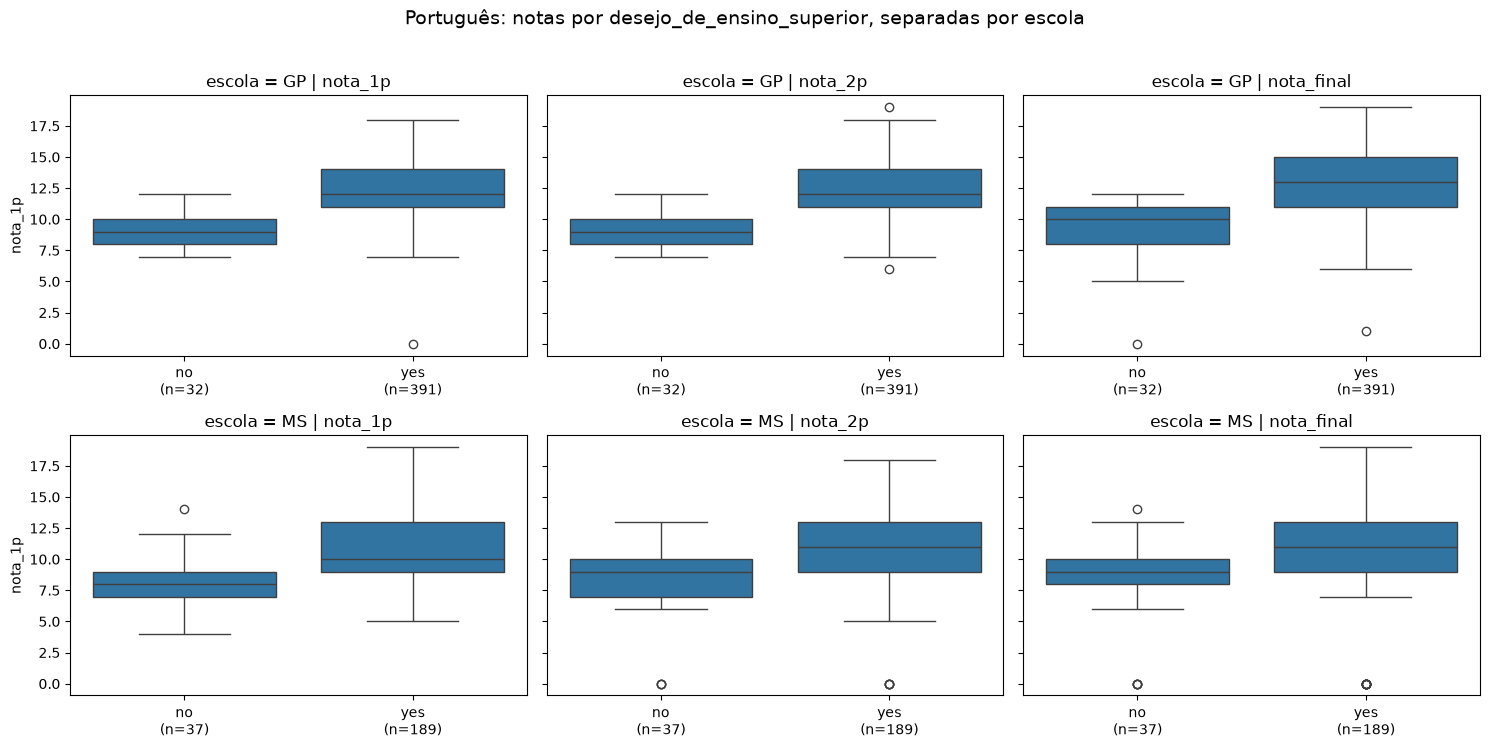

Matemática: média das notas por escola e desejo_de_ensino_superior
                                    n  nota_1p  nota_2p  nota_final
escola desejo_de_ensino_superior                                   
GP     no                          17     7.76     7.35        6.12
       yes                        332    11.10    10.96       10.71
MS     no                           3    11.67    10.33       10.67
       yes                         43    10.60    10.19        9.79

Diferença de média (yes - no) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         3.34     3.60        4.60
MS        -1.06    -0.15       -0.88


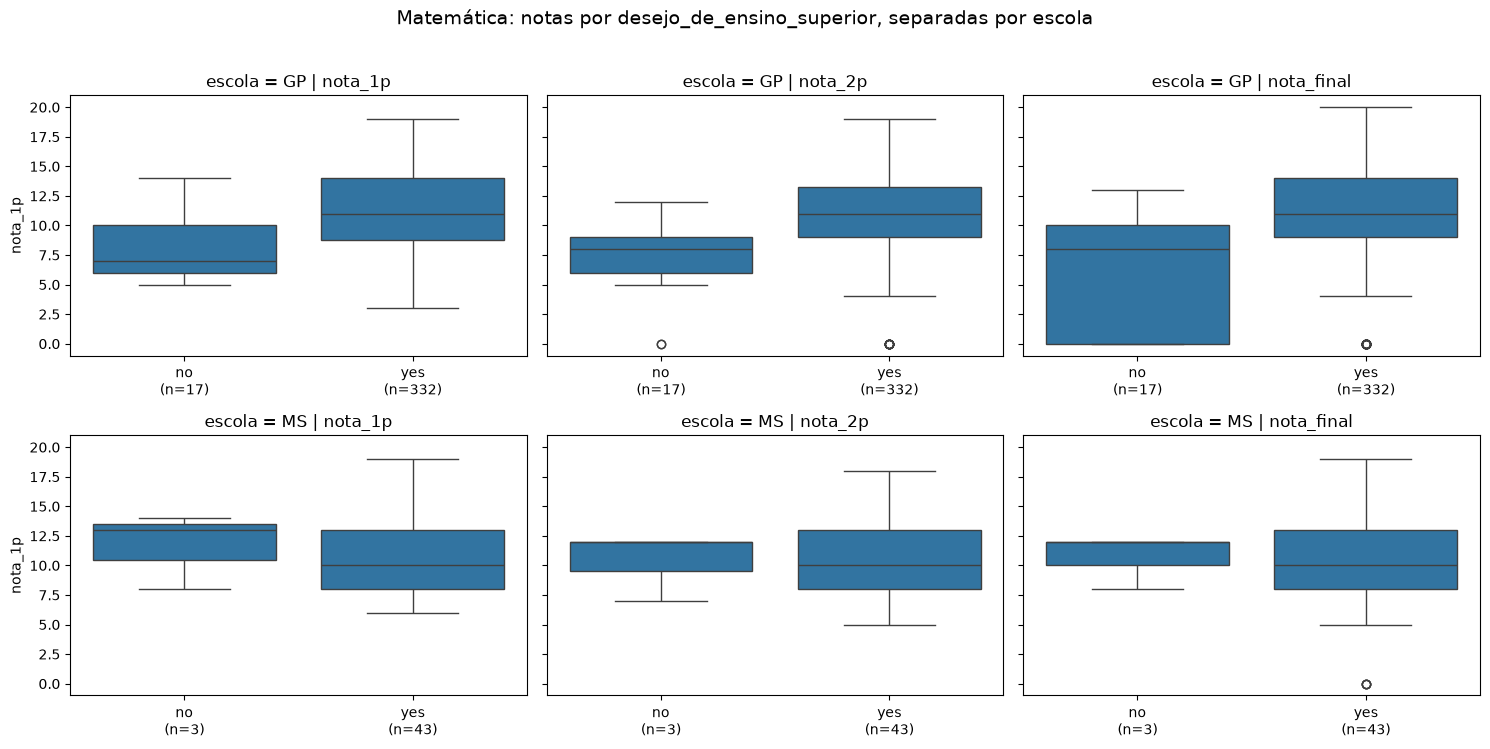

In [29]:
notas = ["nota_1p", "nota_2p", "nota_final"]

boxplots_por_lente(df_port, notas, "desejo_de_ensino_superior", "escola", titulo="Português")
boxplots_por_lente(df_mat, notas, "desejo_de_ensino_superior", "escola", titulo="Matemática")

Percebemos que não podemos olhar para essa questão do desejo da faculdade na matéria de matemática como uma resposta, porque a quantidade do grupo que não deseja a faculdade é extremamente pequeno. 

## Olhando agora para a região

Português: média das notas por escola e regiao
                 n  nota_1p  nota_2p  nota_final
escola regiao                                   
GP     R        78    11.63    11.60       12.14
       U       345    12.07    12.27       12.68
MS     R       119    10.17    10.42       10.39
       U       107    10.45    10.58       10.93

Diferença de média (U - R) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         0.44     0.66        0.53
MS         0.28     0.16        0.54


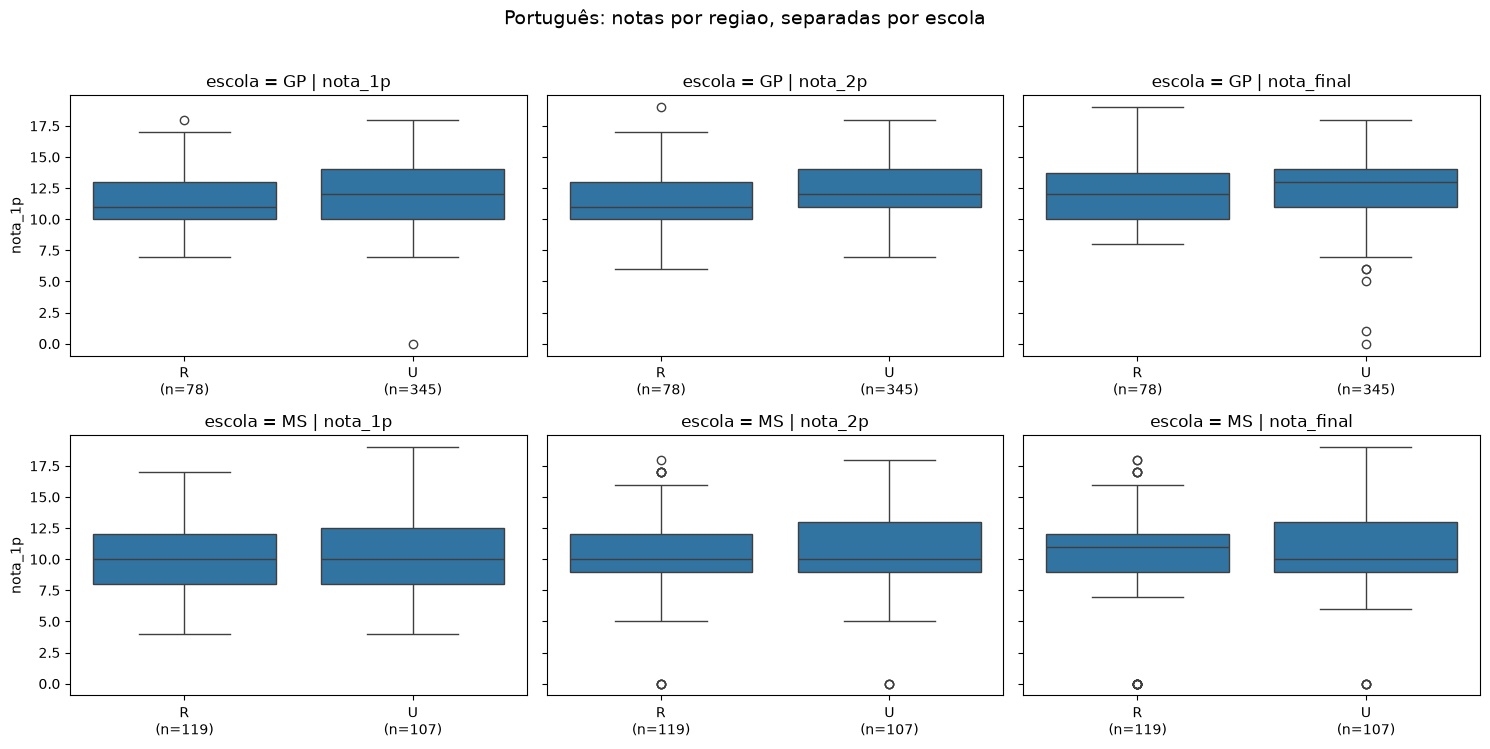

Matemática: média das notas por escola e regiao
                 n  nota_1p  nota_2p  nota_final
escola regiao                                   
GP     R        63    10.68    10.03        9.76
       U       286    11.00    10.95       10.65
MS     R        25     9.96     9.32        8.88
       U        21    11.52    11.24       11.00

Diferença de média (U - R) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         0.31     0.92        0.89
MS         1.56     1.92        2.12


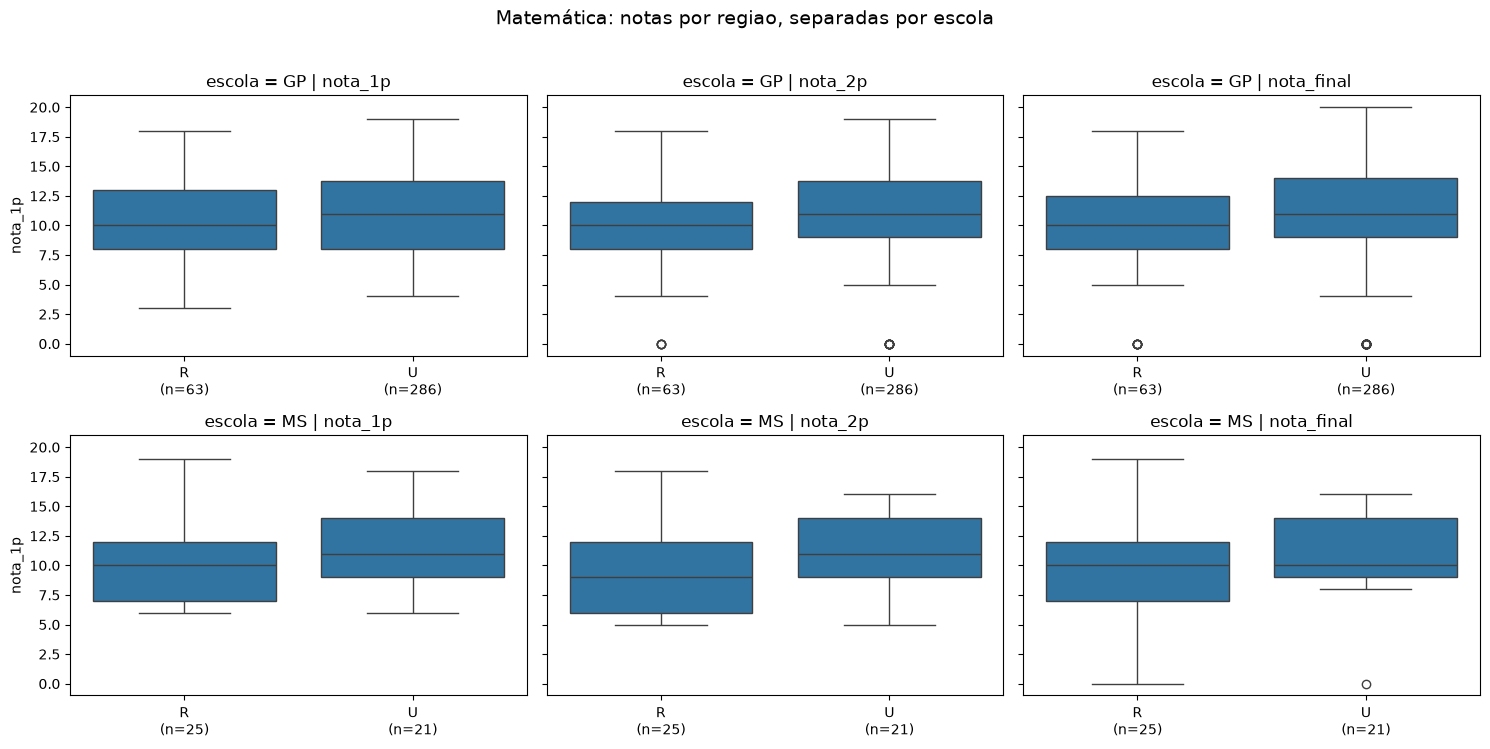

In [30]:
boxplots_por_lente(df_port, notas, "regiao", "escola", titulo="Português")
boxplots_por_lente(df_mat, notas, "regiao", "escola", titulo="Matemática")

# Relação das notas dos sexos entre as escolas


Português: média das notas por escola e sexo
               n  nota_1p  nota_2p  nota_final
escola sexo                                   
GP     F     237    12.29    12.50       13.00
       M     186    11.60    11.69       12.03
MS     F     146    10.58    10.72       11.03
       M      80     9.79    10.09        9.95

Diferença de média (M - F) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP        -0.68    -0.81       -0.97
MS        -0.79    -0.63       -1.08


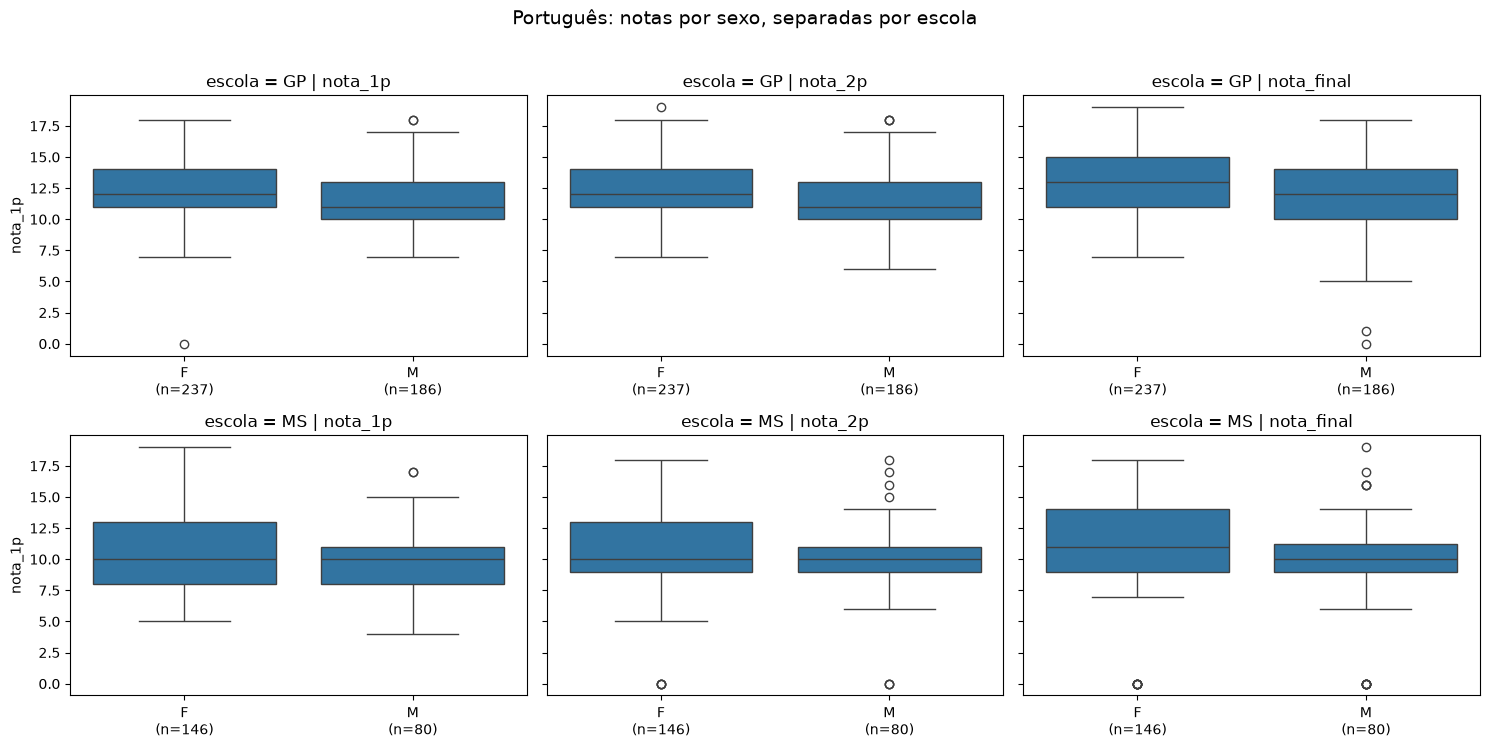

In [31]:
boxplots_por_lente(df_port, notas, "sexo", "escola", titulo="Português")

Matemática: média das notas por escola e sexo
               n  nota_1p  nota_2p  nota_final
escola sexo                                   
GP     F     183    10.58    10.40        9.97
       M     166    11.34    11.20       11.06
MS     F      25    10.92    10.32        9.92
       M      21    10.38    10.05        9.76

Diferença de média (M - F) dentro de cada escola:
        nota_1p  nota_2p  nota_final
escola                              
GP         0.76     0.81        1.09
MS        -0.54    -0.27       -0.16


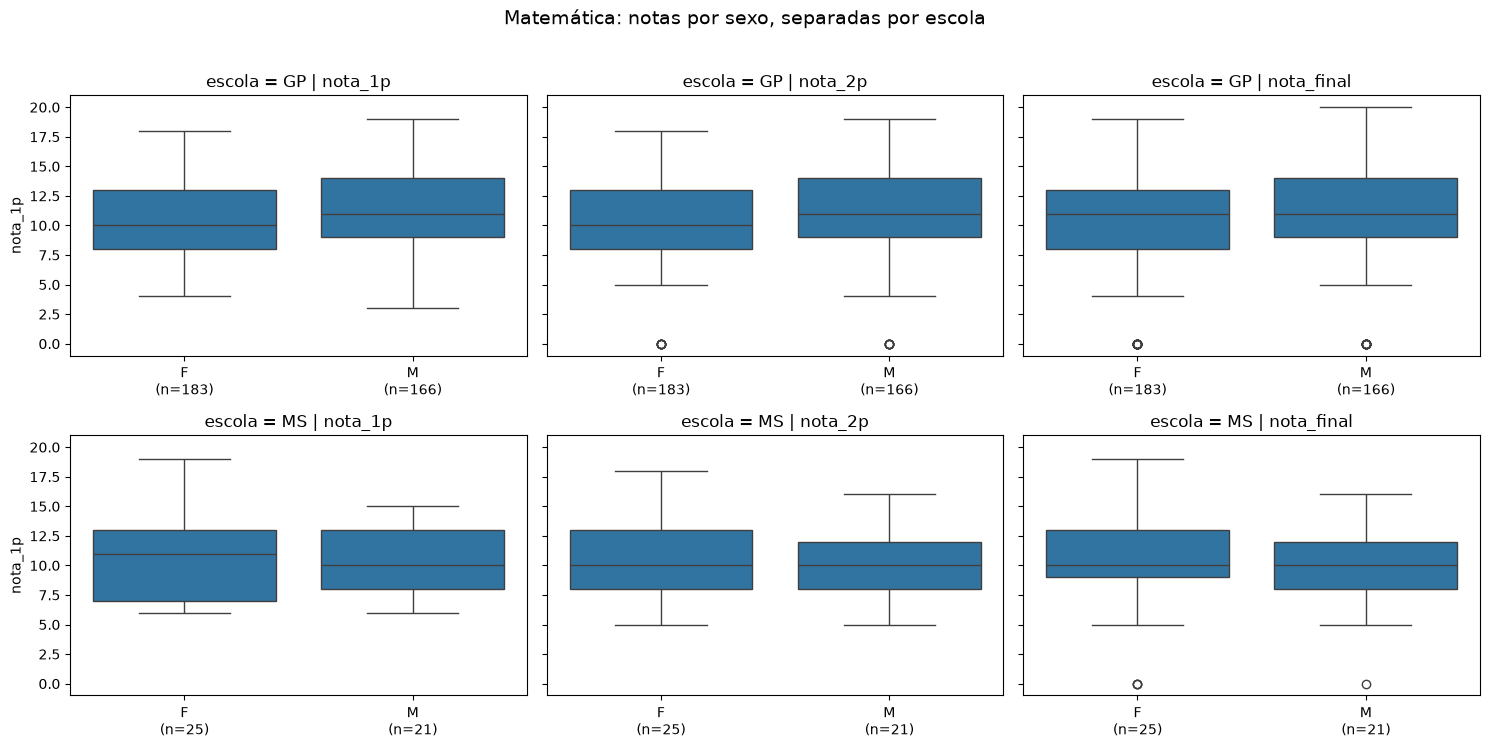

In [32]:
boxplots_por_lente(df_mat, notas, "sexo", "escola", titulo="Matemática")